In [ ]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator

import numpy as np
import matplotlib.pyplot as plt
import os

from scipy.stats import norm

from src.metrics import energy_distance

import torch

from joblib import Parallel, delayed

# Motivating Example: Consistency of Density Estimation and Imputation

In [ ]:
class MotivatingExample(DataGenerator):

    def __init__(self, 
                 n=2000, 
                 B=50, 
                 p=0.1, 
                 energy_distance_scale=True, 
                 model_k=(0,20), 
                 alpha=0.7, 
                 n_jobs=13,
                 ):
        super().__init__(distr='Normal', alpha=alpha)
        self.n = n
        self.B = B
        self.p = p
        self.energy_distance_scale = energy_distance_scale
        self.model_k = model_k
        self.alpha = alpha
        self.n_jobs = n_jobs

        # quantile of X1, 
        # corr of X1&X2, 
        # energy distance of generation, 
        # energy distance of imputation p0(xmb|xm) and pn(xmb|xm)
        self.results = np.empty((self.B, 4)) 

    def _get_Xtildes(self, X, M):
        model = GaussianMixtureMAR(self.model_k)
        model.fit(X, M)
        return model.sample(self.n)[0], model.impute(X, M)

    def _conditional(self, x):
        mean = self.alpha * x
        std = torch.sqrt(torch.tensor(1.0 - self.alpha**2, device=x.device))
        return torch.distributions.Normal(mean, std).sample()

    def _get_conditional_Xtest(self, X, M):
        """
        p0(xmb|xm)
        """
        Xt1 = X.clone()
        Xt2 = X.clone()
        Xt1[:,0] = self._conditional(X[:,1])
        Xt2[:,1] = self._conditional(X[:,0])
        cond1 = (M==1).all(dim=1)[:, None] # all observed
        cond2 = (M==torch.tensor([0,1,1], device=M.device)).all(dim=1)[:, None] # X1 missing
        return torch.where(cond1, X, torch.where(cond2, Xt1, Xt2))

    def _evaluate(self):
        X = self.sample_truth(self.n, 3)
        M = self.generate_MAR(X)
        Xtest1 = self.sample_truth(self.n, 3)
        Xtest2 = self._get_conditional_Xtest(X, M)
        Xtilde1, Xtilde2 = self._get_Xtildes(X, M)
        qx1 = np.quantile(Xtilde1[:,0], self.p).item()
        corr = torch.corrcoef(Xtilde1[:, :2].T)[0, 1].item()
        ed_gen = energy_distance(Xtest1, Xtilde1).item()
        ed_imp = energy_distance(Xtest2, Xtilde2).item()
        return qx1, corr, ed_gen, ed_imp

    def evaluate_all(self):
        self.results = np.array(
            Parallel(self.n_jobs)(
                delayed(self._evaluate)()
                for _ in range(self.B)
            )
        )
        return self

    def plot_results(self):
        fig, axes = plt.subplots(
            2, 2,
            figsize=(12, 6),
            gridspec_kw={
                "wspace": 0.45,  # horizontal spacing
                "hspace": 0.45,  # vertical spacing
            }
        )
        axes = axes.ravel()

        panels = [
            {
                "data": [self.results[:, 0]],
                "labels": ["Generation"],
                "xlabel": r"10% quantile estimate of $X_1$",
                "reference": norm.ppf(0.1),
                "reference_label": f"Truth: {round(norm.ppf(0.1), 3)}",
                "color": "#8DA0CB"
            },
            {
                "data": [self.results[:, 1]],
                "labels": ["Generation"],
                "xlabel": r"Correlation estimate of $X_1$ and $X_2$",
                "reference": self.alpha,
                "reference_label": f"Truth: {self.alpha}",
                "color": "#8DA0CB"
            },
            {
                "data": [self.results[:, 2].round(3) * 1e3],
                "labels": ["Generation"],
                "xlabel": r"Energy distance $\times 10^{3}$",
                "reference": None,
                "reference_label": None,
                "color": "#8DA0CB"
            },
            {
                "data": [self.results[:, 3].round(3) * 1e3],
                "labels": ["Imputation"],
                "xlabel": r"Energy distance $\times 10^{3}$",
                "reference": None,
                "reference_label": None,
                "color": "#FC8D62"
            },
        ]


        for ax, panel in zip(axes, panels):
            data = [
                np.asarray(x).ravel()
                for x in panel["data"]
            ]
            positions = np.arange(1, len(data) + 1)

            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1.2)
                spine.set_color("black")

            # Horizontal violin plots
            vp = ax.violinplot(
                data,
                positions=positions,
                orientation="horizontal",
                widths=0.6,
                showmeans=False,
                showmedians=False,
                showextrema=False,
            )

            for i, body in enumerate(vp["bodies"]):
                body.set_facecolor(panel["color"])
                body.set_edgecolor("black")
                body.set_alpha(0.6)
                body.set_linewidth(0.9)

            # Overlay horizontal box plots
            bp = ax.boxplot(
                data,
                positions=positions,
                orientation="horizontal",
                widths=0.15,
                patch_artist=True,
                showfliers=False,
                medianprops={"color": "black", "linewidth": 1.8},
                whiskerprops={"linewidth": 1.2},
                capprops={"linewidth": 1.2},
                boxprops={"edgecolor": "black", "linewidth": 1.0},
            )

            for box in bp["boxes"]:
                box.set_facecolor("white")
                box.set_alpha(0.9)

            ax.set_yticks(positions, panel["labels"], fontweight="bold")
            # ax.tick_params(axis="y", labelrotation=90, labelsize=12)
            ax.set_title(panel["xlabel"], fontsize=16,) #fontweight="bold")
            ax.tick_params(axis="both", labelsize=14)
        # ax.grid(axis="x", linestyle="--", alpha=0.3)
            ax.set_axisbelow(True)
            # ax.spines["top"].set_visible(False)
            # ax.spines["right"].set_visible(False)
            

            if panel["reference"] is not None:
                ax.axvline(
                    panel["reference"],
                    color="#D62728",
                    linestyle="--",
                    linewidth=1.8,
                    label=panel["reference_label"],
                )
                ax.legend(fontsize=11, frameon=False, loc="best")

        # fig.suptitle(
        #     "Estimator performance across simulation runs",
        #     fontsize=18,
        #     fontweight="bold",
        # )

        os.makedirs("results/figs", exist_ok=True)
        fig.savefig(
            "results/figs/motivating_example_results.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

Using quantile of $X_1$ to evaluate the imputation is acutally not right since the imputed sample represents a partion that is conditioned on the observed, therefore, the numerically computed quantile is quantile of the conditonal rather than the quantile of the marginal!

Therefore, we can only use quantile of marginal to evaluate the estimation performance. We can also use energy distance to evaluate the estimation performance.

When evaluating the performance of the imputation, we compare the imputed sample of the missing part, and the true conditional!

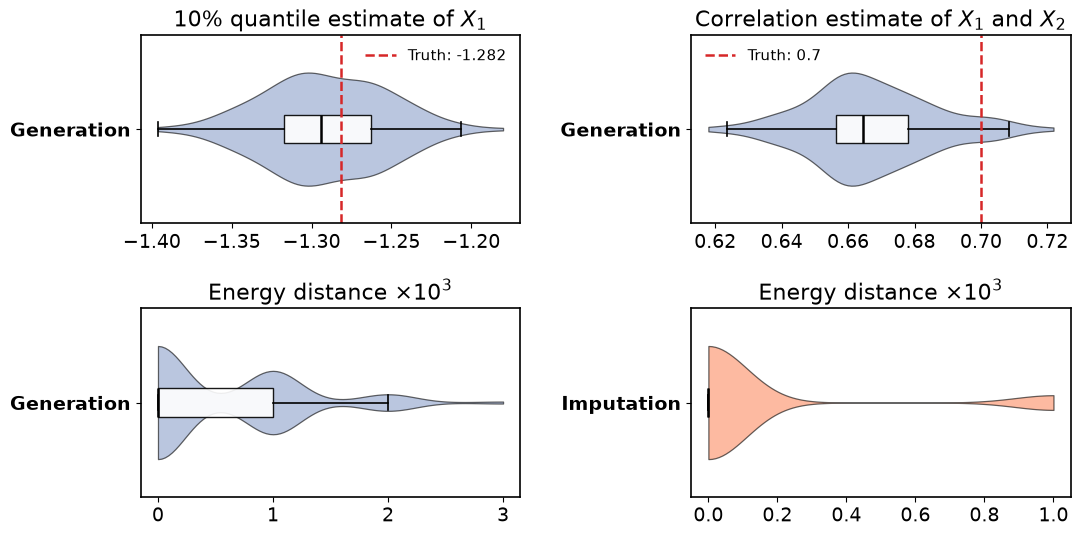

In [5]:
motexp = MotivatingExample(n=5000, B=200, n_jobs=15)
motexp.evaluate_all()
motexp.plot_results()